### Import

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from msuthemes import theme_msu, colors


### Configuration of Paths, Variables, and Load Precomputed Results

In [23]:
# --- CONFIGURATION ---
RESULTS_DIR = "h1_results"
OUTPUT_PLOT = os.path.join(RESULTS_DIR, "Master_H1_Analysis.png")

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']

# Custom mapping for clean plot titles
signal_titles = {
    'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y', 
    'Pupil_Mean': 'Pupil Dilation', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'
}

# Load the summary stats to put exact numbers in titles
stats_df = pd.read_csv(os.path.join(RESULTS_DIR, "h1_summary_stats.csv")).set_index('Signal')

### Set up Helper Functions and (Pre)Compute Results

/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/schmaelz/miniconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future

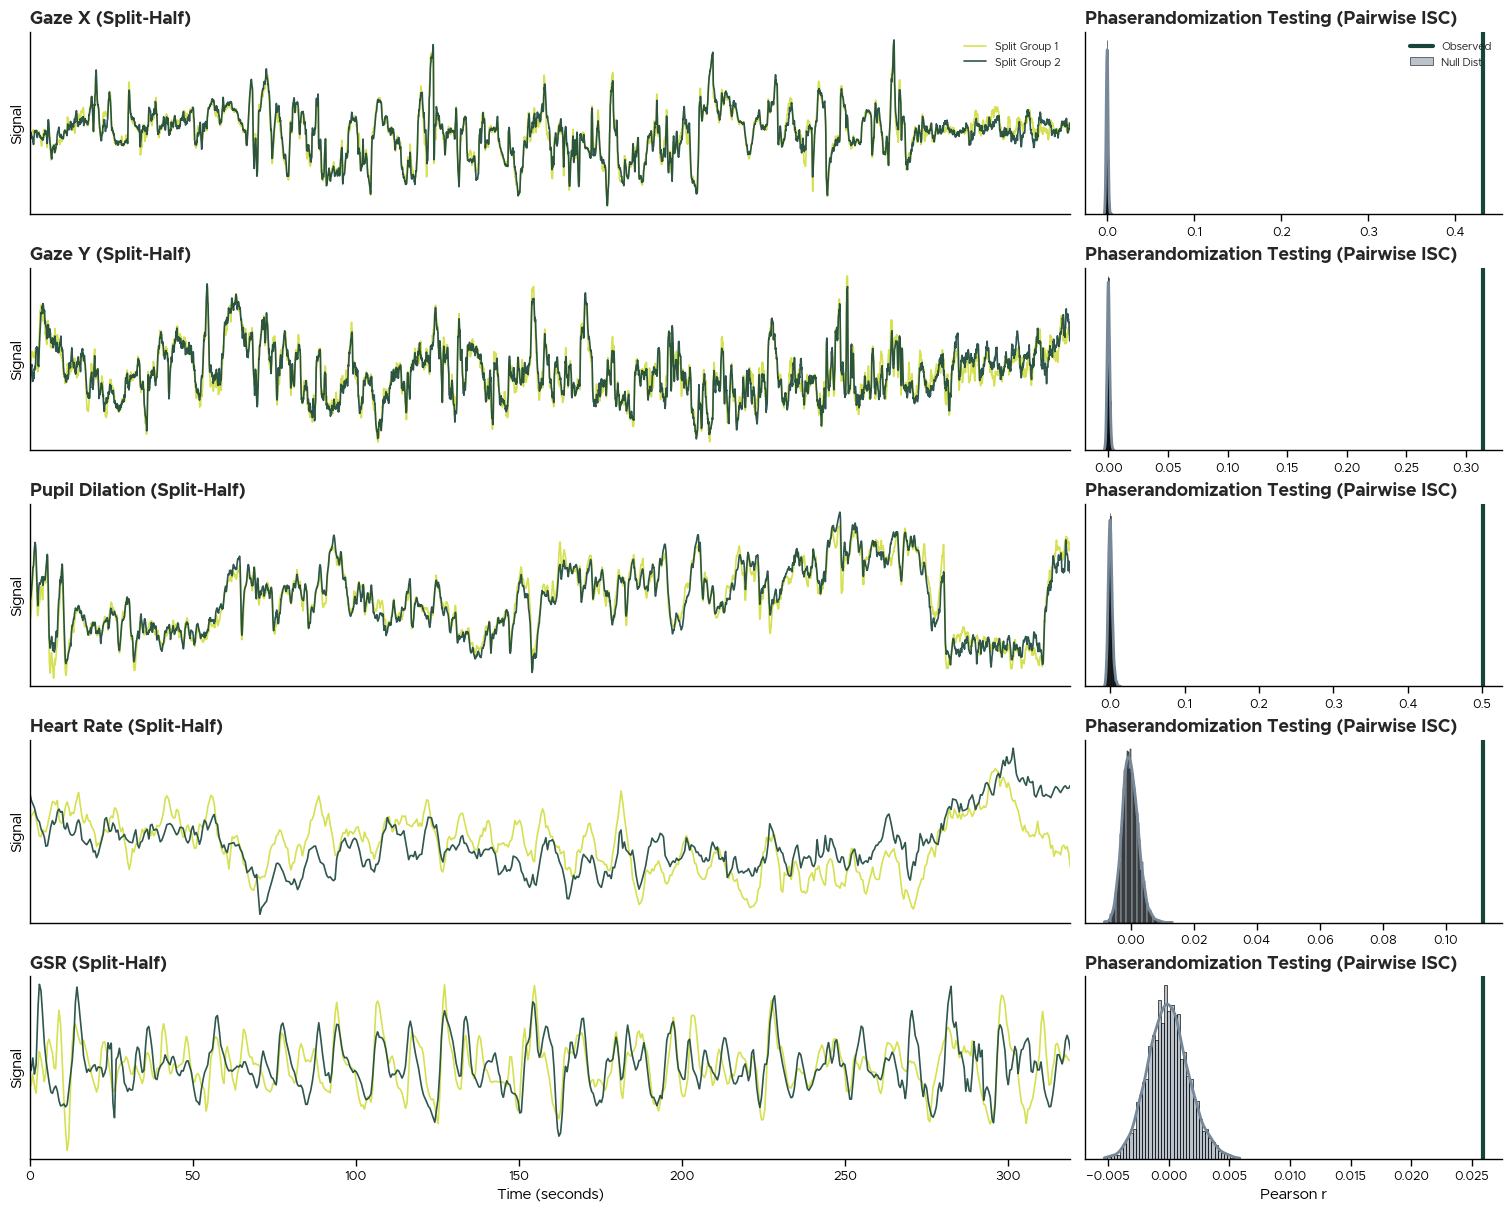

Final Master figure saved to h1_results/Master_H1_Analysis.png


In [24]:

sns.set(style="ticks", context="talk")
theme_msu()


# 1. Adjusted Ratio: 2.5 to 1 (Balanced)
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 12), 
                         gridspec_kw={'width_ratios': [2.5, 1]}, 
                         constrained_layout=True)

for i, signal in enumerate(signals):
    
    # Get stats
    r_split = stats_df.loc[signal, 'Split_Half_r']
    obs_isc = stats_df.loc[signal, 'Observed_ISC']
    p_val = stats_df.loc[signal, 'Phase_Rand_P']
    
    # ==========================
    # LEFT COLUMN: TIMECOURSE
    # ==========================
    ax_tc = axes[i, 0]
    tc_df = pd.read_csv(os.path.join(RESULTS_DIR, f"{signal}_split_timecourse.csv"))
    
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_1'], color=colors.MSU_GRELLOW, alpha=0.9, lw=1.2, label='Split Group 1')
    ax_tc.plot(tc_df['Time_Sec'], tc_df['Group_2'], color=colors.MSU_GREEN, alpha=0.9, lw=1.2, label='Split Group 2')
    
    # Title
    ax_tc.set_title(f"{signal_titles[signal]} (Split-Half)", fontweight='bold', fontsize=13, loc='left')
    
    # Clean Y-Axis (Remove Z-score labels)
    ax_tc.set_ylabel("Signal")   
    ax_tc.set_yticks([])   
    ax_tc.set_xlim(tc_df['Time_Sec'].min(), tc_df['Time_Sec'].max())
    
    # Clean X-Axis (Only show on bottom row)
    if i < 4: 
        ax_tc.set_xticklabels([])
        ax_tc.set_xlabel("")
        ax_tc.tick_params(bottom=False) # Hide the tick marks too
    else: 
        ax_tc.set_xlabel("Time (seconds)", fontsize=11)


    # ==========================
    # RIGHT COLUMN: HISTOGRAMS
    # ==========================
    ax_null = axes[i, 1]
    null_dist = np.load(os.path.join(RESULTS_DIR, f"{signal}_null_dist.npy"))
    
    sns.histplot(null_dist, kde=True, color='lightslategrey', alpha=0.5, ax=ax_null, label='Null Dist')
    ax_null.axvline(obs_isc, color= colors.MSU_GREEN, linestyle='-', linewidth=3, label='Observed')
    
    # Title
    ax_null.set_title(f"Phaserandomization Testing (Pairwise ISC)", fontweight='bold', fontsize=13, loc='left')
    
    # Clean Y-Axis
    ax_null.set_ylabel("") 
    ax_null.set_yticks([]) 
    
    # KEEP X-Axis for ALL rows (because scales differ)
    ax_null.tick_params(axis='x', labelsize=9) # Make numbers slightly smaller to fit
    # We only label the axis text on the bottom to save vertical space, 
    # but we keep the numbers (ticks) on all rows.
    if i == 4:
        ax_null.set_xlabel("Pearson r", fontsize=11)
    else:
        ax_null.set_xlabel("")

# --- FINAL TOUCHES ---
# Legends (First row only)
axes[0,0].legend(loc='upper right', fontsize=8, frameon=False)
axes[0,1].legend(loc='upper right', fontsize=8, frameon=False)

sns.despine()

plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Final Master figure saved to {OUTPUT_PLOT}")